# BEATs audio embeddings: 2D PCA by weld class

Encode the Intel welding audio with the local pretrained **BEATs** encoder and project the embeddings onto two principal components. Each point represents one recording. Its color is the dataset class: **correct** (`CATEGORY == "Good"`) or **incorrect** (any defect category), rather than whether a model prediction was correct.

For each recording, use 2-second audio windows, mean-pool BEATs tokens within each window, and average the window embeddings. Audio preprocessing matches `encoder_test_results.ipynb`: first channel, resampled to 16 kHz, then BEATs' built-in normalized log-mel preprocessing. The encoder is frozen; no classifier or autoencoder is trained.

Use the project's Python environment with `requirements.txt`, plus `matplotlib` and `ipykernel`, as the kernel, then **Run All**. The local checkpoint and extracted dataset are required. Encoding all recordings can take a while on CPU. For a quick preview, set `MAX_RECORDINGS_PER_CLASS = 10` and `MAX_WINDOWS_PER_RECORDING = 1`; leave both as `None` to use the full dataset and all windows.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
import wandb
from IPython.display import display
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader, Dataset

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/encoders.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from the AI360-Project repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from encoders import load_beats

CHECKPOINT = ROOT / "models/BEATs_iter3.pt"
DATA_ROOT = ROOT / "data/intel_robotic_welding_extracted/raid/intel_robotic_welding_dataset"
MANIFEST = DATA_ROOT / "manifest.csv"
OUTPUT_DIR = ROOT / "artifacts/beats_pca"
SPLITS = ("TRAIN", "VAL", "TEST")  # TRAIN alone contains only correct welds.
SAMPLE_RATE = 16_000
CLIP_SECONDS = 2.0
HOP_SECONDS = 2.0
BATCH_SIZE = 4
MAX_RECORDINGS_PER_CLASS = None  # Optional reproducible class-balanced subset.
MAX_WINDOWS_PER_RECORDING = None  # Optional evenly spaced windows per recording.
RECOMPUTE_EMBEDDINGS = False  # Otherwise reuse a cache with matching inputs/settings.
SEED = 42
WANDB_PROJECT = "beats-welding-pca"  # Override with WANDB_PROJECT if desired.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if CLIP_SECONDS < 0.2 or HOP_SECONDS <= 0 or BATCH_SIZE < 1:
    raise ValueError("Use CLIP_SECONDS >= 0.2, HOP_SECONDS > 0, and BATCH_SIZE >= 1.")
for limit in (MAX_RECORDINGS_PER_CLASS, MAX_WINDOWS_PER_RECORDING):
    if limit is not None and (not isinstance(limit, int) or limit < 1):
        raise ValueError("Optional limits must be positive integers or None.")
if not CHECKPOINT.is_file() or not MANIFEST.is_file():
    raise FileNotFoundError("Set CHECKPOINT, DATA_ROOT, and MANIFEST to the local model and dataset.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Device: {DEVICE}")
# WANDB_ENTITY and WANDB_MODE can be set in the environment.
run = wandb.init(
    project=None if __import__("os").environ.get("WANDB_PROJECT") else WANDB_PROJECT,
    job_type="embedding-visualization",
    config=dict(splits=list(SPLITS), sample_rate=SAMPLE_RATE, clip_seconds=CLIP_SECONDS,
                hop_seconds=HOP_SECONDS, batch_size=BATCH_SIZE,
                max_recordings_per_class=MAX_RECORDINGS_PER_CLASS,
                max_windows_per_recording=MAX_WINDOWS_PER_RECORDING,
                recompute_embeddings=RECOMPUTE_EMBEDDINGS, seed=SEED,
                encoder="BEATs", pooling="token_mean_then_window_mean",
                checkpoint=CHECKPOINT.name, device=str(DEVICE)),
)


Device: cuda


## Read recording labels

Keep the original category and published split alongside the binary class. By default all three splits are included in this exploratory visualization. PCA is fitted to the selected embeddings without using their labels; this plot is not a held-out evaluation.

In [9]:
manifest = pd.read_csv(MANIFEST)
required = {"SUBDIRS", "CATEGORY", "SPLIT"}
if not required.issubset(manifest.columns):
    raise ValueError(f"Manifest must contain {sorted(required)}.")
if manifest[list(required)].isna().any().any():
    raise ValueError("Manifest has missing recording IDs, categories, or splits.")
manifest["CATEGORY"] = manifest.CATEGORY.astype(str).str.strip()
manifest["SPLIT"] = manifest.SPLIT.astype(str).str.strip().str.upper()
if manifest.CATEGORY.eq("").any():
    raise ValueError("Manifest contains an empty category.")
selected = manifest[manifest.SPLIT.isin(SPLITS)].copy()
selected["class"] = np.where(selected.CATEGORY.eq("Good"), "correct", "incorrect")
if MAX_RECORDINGS_PER_CLASS is not None:
    selected = pd.concat([
        group.sample(n=min(len(group), MAX_RECORDINGS_PER_CLASS), random_state=SEED)
        for _, group in selected.groupby("class", sort=True)
    ], ignore_index=True) if len(selected) else selected
if len(selected) < 2:
    raise ValueError("Select at least two recordings for PCA.")
if selected.SUBDIRS.duplicated().any():
    raise ValueError("Manifest contains duplicate recording IDs.")

rows = []
for item in selected.sort_values("SUBDIRS").to_dict("records"):
    folder = DATA_ROOT / str(item["SUBDIRS"])
    audio_files = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".wav", ".flac"})
    if len(audio_files) != 1:
        raise ValueError(f"Expected one WAV/FLAC file in {folder}; found {len(audio_files)}.")
    path = audio_files[0].resolve()
    info = sf.info(str(path))
    if info.duration + 1e-6 < CLIP_SECONDS:
        raise ValueError(f"{path} is shorter than CLIP_SECONDS={CLIP_SECONDS}.")
    rows.append(dict(recording_id=str(item["SUBDIRS"]), category=item["CATEGORY"],
                     split=item["SPLIT"], **{"class": item["class"]}, path=str(path),
                     duration=info.duration, audio_bytes=path.stat().st_size,
                     audio_mtime_ns=path.stat().st_mtime_ns))
recordings = pd.DataFrame(rows)
if recordings.path.duplicated().any():
    raise ValueError("Multiple recording IDs refer to the same audio file.")
display(pd.crosstab(recordings["split"], recordings["class"]))
if recordings["class"].nunique() < 2:
    print("Only one class was selected. Include VAL or TEST to visualize both classes.")
print(f"Selected {len(recordings):,} recordings.")

display(recordings.head())

display(recordings.groupby("category").describe())

class,correct,incorrect
split,,
TEST,121,1611
TRAIN,576,0
VAL,122,1610


Selected 4,040 recordings.


,recording_id,category,split,class,path,duration,audio_bytes,audio_mtime_ns
0,10_crater_cracks_7_03-20-23_Fe410/04-03-23-001...,Crater_Cracks,VAL,incorrect,/home/jaden/Documents/ai-360/AI360-Project/dat...,38.0,506890,1793043347790002806
1,10_crater_cracks_7_03-20-23_Fe410/04-03-23-001...,Crater_Cracks,VAL,incorrect,/home/jaden/Documents/ai-360/AI360-Project/dat...,38.0,499221,1793043347746001373
2,10_good_weld_plane_plate/12-31-22-0015-00,Good,TRAIN,correct,/home/jaden/Documents/ai-360/AI360-Project/dat...,38.0,473111,1793043222046786272
3,10_good_weld_plane_plate/12-31-22-0016-00,Good,TRAIN,correct,/home/jaden/Documents/ai-360/AI360-Project/dat...,38.0,476079,1793043222099788106
4,10_good_weld_plane_plate/12-31-22-0017-00,Good,TRAIN,correct,/home/jaden/Documents/ai-360/AI360-Project/dat...,38.0,466182,1793043222072787172


duration                                 \
                                    count      mean      std   min   25%   
category                                                                   
Burnthrough                         320.0  38.00000  0.00000  38.0  38.0   
Crater_Cracks                       161.0  38.00000  0.00000  38.0  38.0   
Excessive_Convexity                 160.0  38.00000  0.00000  38.0  38.0   
Excessive_Penetration               480.0  38.00000  0.00000  38.0  38.0   
Good                                819.0  38.00000  0.00000  38.0  38.0   
Lack_of_Fusion                      320.0  38.00000  0.00000  38.0  38.0   
Overlap                             160.0  25.08125  1.02774  25.0  25.0   
Porosity                            340.0  38.00000  0.00000  38.0  38.0   
Porosity_w_Excessive_Penetration    480.0  38.00000  0.00000  38.0  38.0   
Spatter                             320.0  38.00000  0.00000  38.0  38.0   
Undercut                            160.0  38.00000  0.00000  38.0  38.0   
Warping                             320.0  38.00000  0.00000  38.0  38.0   

                                                   audio_bytes                 \
                                   50%   75%   max       count           mean   
category                                                                        
Burnthrough                       38.0  38.0  38.0       320.0  511711.434375   
Crater_Cracks                     38.0  38.0  38.0       161.0  537133.496894   
Excessive_Convexity               38.0  38.0  38.0       160.0  537520.987500   
Excessive_Penetration             38.0  38.0  38.0       480.0  514919.914583   
Good                              38.0  38.0  38.0       819.0  510045.507937   
Lack_of_Fusion                    38.0  38.0  38.0       320.0  489262.406250   
Overlap                           25.0  25.0  38.0       160.0  288406.950000   
Porosity                          38.0  38.0  38.0       340.0  533603.055882   
Porosity_w_Excessive_Penetration  38.0  38.0  38.0       480.0  531849.460417   
Spatter                           38.0  38.0  38.0       320.0  498905.750000   
Undercut                          38.0  38.0  38.0       160.0  520189.618750   
Warping                           38.0  38.0  38.0       320.0  477793.575000   

                                  ...                      audio_mtime_ns  \
                                  ...        75%       max          count   
category                          ...                                       
Burnthrough                       ...  535030.25  576132.0          320.0   
Crater_Cracks                     ...  547014.00  586103.0          161.0   
Excessive_Convexity               ...  554970.50  579213.0          160.0   
Excessive_Penetration             ...  533878.75  570796.0          480.0   
Good                              ...  543276.00  601137.0          819.0   
Lack_of_Fusion                    ...  518911.00  545710.0          320.0   
Overlap                           ...  281529.75  558564.0          160.0   
Porosity                          ...  550916.00  599792.0          340.0   
Porosity_w_Excessive_Penetration  ...  560664.50  601640.0          480.0   
Spatter                           ...  534178.00  575506.0          320.0   
Undercut                          ...  533348.50  561057.0          160.0   
Warping                           ...  498286.50  575136.0          320.0   

                                                                            \
                                          mean           std           min   
category                                                                     
Burnthrough                       1.793043e+18  3.185174e+10  1.793043e+18   
Crater_Cracks                     1.793043e+18  4.017030e+10  1.793043e+18   
Excessive_Convexity               1.793043e+18  3.337995e+10  1.793043e+18   
Excessive_Penetration             1.793043e+18  3.72

## Encode audio windows

Add a final window ending at the recording boundary when necessary. Optional window limits select evenly spaced windows across the recording. BEATs returns patch tokens; mean pooling produces one vector per window, then an equal-weight mean produces one vector per recording. No audio padding is used.

The cache stores recording embeddings in the same order as the metadata. It is reused only when the selected files, file sizes/modification times, checkpoint, and encoding settings match. Set `RECOMPUTE_EMBEDDINGS = True` after changing encoder implementation code.

In [3]:
windows = []
window_counts = []
for recording_index, row in recordings.iterrows():
    last_start = max(0.0, row.duration - CLIP_SECONDS)
    starts = np.arange(0, last_start + 1e-6, HOP_SECONDS).tolist()
    if last_start - starts[-1] > 1e-6:
        starts.append(last_start)
    if MAX_WINDOWS_PER_RECORDING is not None and len(starts) > MAX_WINDOWS_PER_RECORDING:
        indices = np.linspace(0, len(starts) - 1, MAX_WINDOWS_PER_RECORDING, dtype=int)
        starts = [starts[i] for i in indices]
    windows.extend((recording_index, row.path, start) for start in starts)
    window_counts.append(len(starts))
recordings["n_windows"] = window_counts

class AudioWindows(Dataset):
    def __len__(self):
        return len(windows)

    def __getitem__(self, index):
        recording_index, path, start_seconds = windows[index]
        with sf.SoundFile(path) as audio:
            source_rate = audio.samplerate
            frames = round(CLIP_SECONDS * source_rate)
            start = min(round(start_seconds * source_rate), max(0, len(audio) - frames))
            audio.seek(start)
            waveform = audio.read(frames, dtype="float32", always_2d=True)
        waveform = torch.from_numpy(waveform[:, 0].copy())
        if source_rate != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(waveform, source_rate, SAMPLE_RATE)
        expected = round(CLIP_SECONDS * SAMPLE_RATE)
        if waveform.numel() < expected:
            raise ValueError(f"Too few audio samples after resampling: {path}")
        waveform = waveform[:expected]
        if not torch.isfinite(waveform).all():
            raise ValueError(f"Non-finite audio samples: {path}")
        return waveform, recording_index

checkpoint_stat = CHECKPOINT.stat()
encoding_settings = dict(
    checkpoint=str(CHECKPOINT.resolve()), checkpoint_bytes=checkpoint_stat.st_size,
    checkpoint_mtime_ns=checkpoint_stat.st_mtime_ns, sample_rate=SAMPLE_RATE,
    clip_seconds=CLIP_SECONDS, hop_seconds=HOP_SECONDS,
    max_windows_per_recording=MAX_WINDOWS_PER_RECORDING, pooling="token_mean_then_window_mean",
    channel=0,
)
fingerprint = hashlib.sha256((json.dumps(encoding_settings, sort_keys=True)
                             + recordings.to_json(orient="records")).encode()).hexdigest()
cache_path = OUTPUT_DIR / "beats_embeddings.npz"
embeddings = None
if cache_path.is_file() and not RECOMPUTE_EMBEDDINGS:
    with np.load(cache_path, allow_pickle=False) as cached:
        if cached["fingerprint"].item() == fingerprint:
            embeddings = cached["embeddings"].copy()
            print(f"Loaded cached embeddings from {cache_path}")

if embeddings is None:
    torch.manual_seed(SEED)
    model = load_beats(CHECKPOINT)
    model.predictor = None  # Always extract encoder tokens, even with a classification checkpoint.
    model.cfg.finetuned_model = False
    model.requires_grad_(False).eval().to(DEVICE)
    loader = DataLoader(AudioWindows(), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=DEVICE.type == "cuda")
    sums = np.zeros((len(recordings), model.cfg.encoder_embed_dim), dtype=np.float64)
    counts = np.zeros(len(recordings), dtype=np.int64)
    print(f"Encoding {len(windows):,} windows in {len(loader):,} batches...", flush=True)
    with torch.inference_mode():
        for batch_number, (waveforms, recording_indices) in enumerate(loader, start=1):
            tokens, _ = model.extract_features(waveforms.to(DEVICE))
            if tokens.ndim != 3:
                raise ValueError(f"Expected [batch, tokens, features], got {tokens.shape}.")
            vectors = tokens.mean(dim=1).cpu().numpy()
            indices = recording_indices.numpy()
            np.add.at(sums, indices, vectors)
            np.add.at(counts, indices, 1)
            if batch_number == 1 or batch_number % 25 == 0 or batch_number == len(loader):
                print(f"Batch {batch_number:,}/{len(loader):,}", flush=True)
    np.testing.assert_array_equal(counts, recordings.n_windows.to_numpy())
    embeddings = (sums / counts[:, None]).astype(np.float32)
    if not np.isfinite(embeddings).all():
        raise ValueError("Encoder produced non-finite embeddings.")
    np.savez_compressed(cache_path, embeddings=embeddings, fingerprint=np.array(fingerprint),
                        recording_ids=recordings.recording_id.to_numpy(dtype=str))
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

if embeddings.ndim != 2 or embeddings.shape[0] != len(recordings) or not np.isfinite(embeddings).all():
    raise ValueError("Embeddings must be a finite matrix with one row per recording.")
recordings.to_csv(OUTPUT_DIR / "recordings.csv", index=False)
(OUTPUT_DIR / "encoding_settings.json").write_text(json.dumps(encoding_settings, indent=2))
print(f"Embedding matrix: {embeddings.shape} (recordings × features)")

/home/jaden/Documents/ai-360/AI360-Project/.venv/lib/python3.14/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Encoding 75,806 windows in 18,952 batches...
Batch 1/18,952
Batch 25/18,952
Batch 50/18,952
Batch 75/18,952
Batch 100/18,952
Batch 125/18,952
Batch 150/18,952
Batch 175/18,952
Batch 200/18,952
Batch 225/18,952
Batch 250/18,952
Batch 275/18,952
Batch 300/18,952
Batch 325/18,952
Batch 350/18,952
Batch 375/18,952
Batch 400/18,952
Batch 425/18,952
Batch 450/18,952
Batch 475/18,952
Batch 500/18,952
Batch 525/18,952
Batch 550/18,952
Batch 575/18,952
Batch 600/18,952
Batch 625/18,952
Batch 650/18,952
Batch 675/18,952
Batch 700/18,952
Batch 725/18,952
Batch 750/18,952
Batch 775/18,952
Batch 800/18,952
Batch 825/18,952
Batch 850/18,952
Batch 875/18,952
Batch 900/18,952
Batch 925/18,952
Batch 950/18,952
Batch 975/18,952
Batch 1,000/18,952
Batch 1,025/18,952
Batch 1,050/18,952
Batch 1,075/18,952
Batch 1,100/18,952
Batch 1,125/18,952
Batch 1,150/18,952
Batch 1,175/18,952
Batch 1,200/18,952
Batch 1,225/18,952
Batch 1,250/18,952
Batch 1,275/18,952
Batch 1,300/18,952
Batch 1,325/18,952
Batch 1,350/18

## Fit PCA and plot by class

Apply PCA directly to the mean-pooled embeddings. Scikit-learn centers each feature; no per-feature standardization is applied. Axis labels show the fraction of embedding variance explained by each component. Colors use ground-truth weld class, and the same PCA fit serves both classes.

embedding shape: (4040, 768)


TypeError: FigureCanvasAgg.print_png() got an unexpected keyword argument 'bbozx_inches'

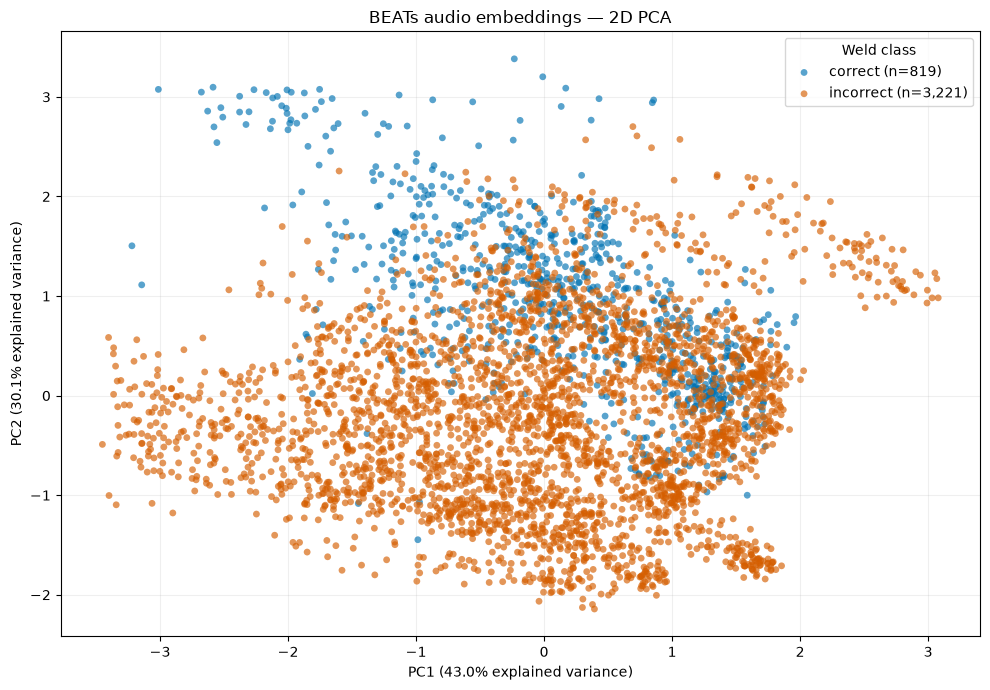

In [11]:
print("embedding shape:", embeddings.shape)
if min(embeddings.shape) < 2 or not np.any(np.var(embeddings, axis=0) > 0):
    raise ValueError("PCA needs at least two non-identical embeddings and two features.")
pca = PCA(n_components=2, svd_solver="full")
coordinates = pca.fit_transform(embeddings)
projection = recordings.copy()
projection["PC1"], projection["PC2"] = coordinates[:, 0], coordinates[:, 1]
variance = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(10, 7))
colors = {"correct": "#0072B2", "incorrect": "#D55E00"}
for label, color in colors.items():
    points = projection.loc[projection["class"].eq(label)]
    if len(points):
        ax.scatter(points.PC1, points.PC2, c=color, s=24, alpha=0.65,
                   edgecolors="none", label=f"{label} (n={len(points):,})")
ax.set(title="BEATs audio embeddings — 2D PCA",
       xlabel=f"PC1 ({variance[0]:.1f}% explained variance)",
       ylabel=f"PC2 ({variance[1]:.1f}% explained variance)")
ax.legend(title="Weld class")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "beats_pca_2d.png", dpi=180, bbox_inches="tight")
wandb.log({"pca/plot": wandb.Image(fig),
           "pca/pc1_explained_variance": float(pca.explained_variance_ratio_[0]),
           "pca/pc2_explained_variance": float(pca.explained_variance_ratio_[1]),
           "pca/total_explained_variance": float(pca.explained_variance_ratio_.sum())})
plt.show()

projection.to_csv(OUTPUT_DIR / "beats_pca_2d.csv", index=False)
np.savez_compressed(OUTPUT_DIR / "pca_transform.npz", components=pca.components_,
                    mean=pca.mean_, explained_variance_ratio=pca.explained_variance_ratio_)
print(f"PC1 + PC2 explain {variance.sum():.1f}% of embedding variance.")
print(f"Saved plot, coordinates, embeddings, recording metadata, and PCA transform to {OUTPUT_DIR}")

perplexity:  20.0


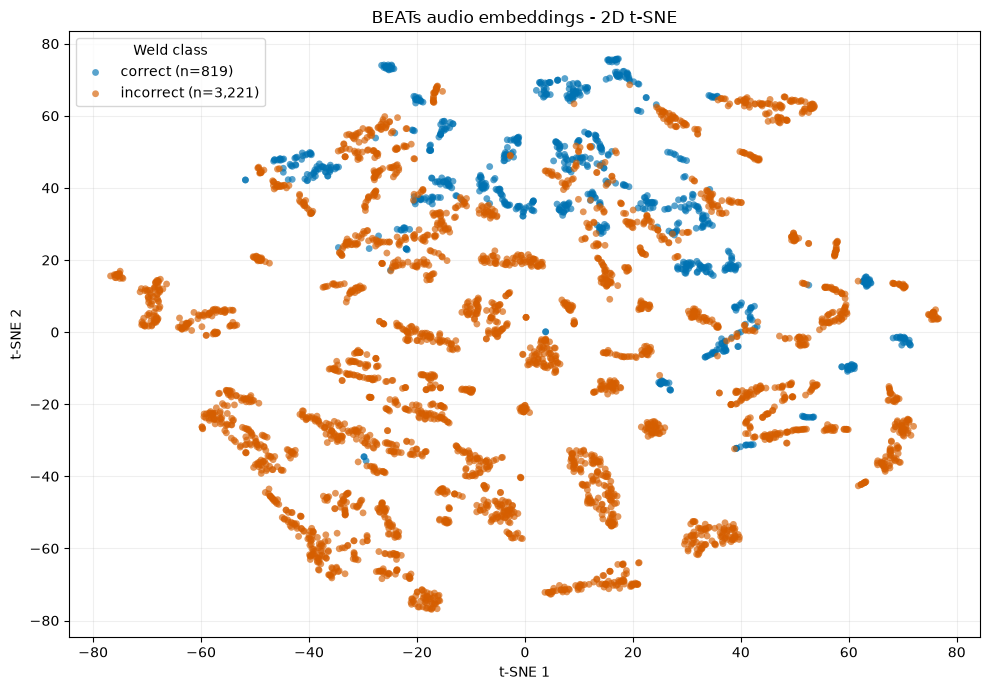

t-SNE perplexity: 20.0
Saved t-SNE plot and coordinates to /home/jaden/Documents/ai-360/AI360-Project/artifacts/beats_pca


In [13]:
from sklearn.manifold import TSNE

if embeddings.shape[0] < 3 or not np.any(np.var(embeddings, axis=0) > 0):
    raise ValueError("t-SNE needs at least three non-identical embeddings.")
perplexity = min(20.0, max(2.0, (len(embeddings) - 1) / 3))
print("perplexity: ", perplexity)
tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED)
coordinates = tsne.fit_transform(embeddings)
projection = recordings.copy()
projection["TSNE1"], projection["TSNE2"] = coordinates[:, 0], coordinates[:, 1]

fig, ax = plt.subplots(figsize=(10, 7))
colors = {"correct": "#0072B2", "incorrect": "#D55E00"}
for label, color in colors.items():
    points = projection.loc[projection["class"].eq(label)]
    if len(points):
        ax.scatter(points.TSNE1, points.TSNE2, c=color, s=24, alpha=0.65,
                   edgecolors="none", label=f"{label} (n={len(points):,})")
ax.set(title="BEATs audio embeddings - 2D t-SNE",
       xlabel="t-SNE 1", ylabel="t-SNE 2")
ax.legend(title="Weld class")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "beats_tsne_2d.png", dpi=180, bbox_inches="tight")
wandb.log({"tsne/plot": wandb.Image(fig), "tsne/perplexity": perplexity})
plt.show()

projection.to_csv(OUTPUT_DIR / "beats_tsne_2d.csv", index=False)
print(f"t-SNE perplexity: {perplexity:.1f}")
print(f"Saved t-SNE plot and coordinates to {OUTPUT_DIR}")

Overlap in this plot means only that the first two principal components overlap; separation could exist in other dimensions. PCA maximizes variance, not class separation. Recording duration, welding setup, or other acquisition conditions may also shape the projection. Use the existing evaluation notebook for classification/anomaly-detection metrics.

## Upload experiment outputs

The artifact contains the notebook, plots, projections, embeddings, metadata, and PCA transform. Local recording paths are removed from the uploaded CSV files. Authenticate with `wandb login` before running, or set `WANDB_MODE=offline` to sync later.


In [ ]:
import tempfile

run.summary["recordings"] = len(recordings)
run.summary["windows"] = len(windows)
run.summary["embedding_dimensions"] = embeddings.shape[1]
for label, count in recordings["class"].value_counts().items():
    run.summary[f"class_counts/{label}"] = int(count)

# Stage sanitized metadata separately so local filesystem paths are not uploaded.
with tempfile.TemporaryDirectory() as staging:
    staging = Path(staging)
    artifact = wandb.Artifact("beats-welding-projections", type="experiment-results")
    for name in ("recordings.csv", "beats_pca_2d.csv", "beats_tsne_2d.csv"):
        df = pd.read_csv(OUTPUT_DIR / name).drop(columns=["path"], errors="ignore")
        df.to_csv(staging / name, index=False)
        artifact.add_file(str(staging / name), name=name)
    for name in ("beats_pca_2d.png", "beats_tsne_2d.png", "beats_embeddings.npz", "pca_transform.npz"):
        artifact.add_file(str(OUTPUT_DIR / name), name=name)
    # Checkpoint paths are local machine details; retain its name and other settings.
    public_settings = {**encoding_settings, "checkpoint": CHECKPOINT.name}
    (staging / "encoding_settings.json").write_text(json.dumps(public_settings, indent=2))
    artifact.add_file(str(staging / "encoding_settings.json"), name="encoding_settings.json")
    artifact.add_file(str(ROOT / "beats_pca.ipynb"), name="beats_pca.ipynb")
    run.log_artifact(artifact)
    run.finish()
